## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

---

### Dataset structure

| Column Name | Description |
| :--- | :--- |
| **uid** | Unique identifier for each row. |
| **asin** | Product ID from Amazon. |
| **title** | Title of the product. |
| **stars** | Product rating. If 0, no ratings were found. |
| **reviews** | Number of customer reviews. If 0, no ratings were found. |
| **price** | Price of the product. (Currency: GBP) |
| **isBestSeller** | Product category indicator/Best seller status. |
| **boughtInLastMonth** | Whether the product was bought in the last month. |
| **category** | Indicates products category. |



## Download the Dataset

In [1]:

import kagglehub
from kagglehub import KaggleDatasetAdapter
from IPython.display import clear_output

# Filepath to the dataset
file_path = "amz_uk_price_prediction_dataset.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "asaniczka/uk-optimal-product-price-prediction",
  file_path,
)

clear_output()
print("Dataset loaded successfully!")


Dataset loaded successfully!


### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*



In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline
pd.set_option('display.max_columns', None)

In [3]:
categorical_df = df.select_dtypes(exclude="number")
numeric_df = df.select_dtypes(include="number")

In [4]:
print(categorical_df.shape)
print(numeric_df.shape)

(2443651, 4)
(2443651, 5)


In [5]:
categorical_df.columns

Index(['asin', 'title', 'isBestSeller', 'category'], dtype='str')

In [6]:
# A table showing the frequency of occurrences for combinations 
# of the two categorical variables: category and isBestSeller
crosstab_norm = pd.crosstab(categorical_df.category, categorical_df.isBestSeller, normalize="index")

# Top 5: Normalized
crosstab_norm_sorted = crosstab_norm.sort_values(True, ascending=False)
display(crosstab_norm_sorted[:5])


isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339


The Top categories that have the most best sellers: 

In [7]:
# A table showing the frequency of occurrences for combinations 
# of the two categorical variables: category and isBestSeller
crosstab_freq = pd.crosstab(categorical_df.category, categorical_df.isBestSeller, normalize=False)

# Top 5: Normalized
crosstab_freq = crosstab_freq.sort_values(True, ascending=False)
display(crosstab_freq[:5])

isBestSeller,False,True
category,,
Grocery,9008,556
Health & Personal Care,9017,552
Baby,14709,341
Sports & Outdoors,835935,330
Power & Hand Tools,8353,306


In [8]:
from IPython.display import Markdown

top_5_percentage = crosstab_norm_sorted[:5].index.to_list()
top_5_volume = crosstab_freq[:5].index.to_list()
categories = ", ".join(top_5_percentage)
categories_volume = ", ".join(top_5_volume)

n_intersection = len([item for item in top_5_volume if item in top_5_percentage ])

report = f"""
#### Conclusion: Analyzing Best-Seller Trends Across Product Categories

The analysis of the categorical variables 'category' and 'isBestSeller' was conducted using the crosstab approach and normalizing by
the index. The top 5 categories with the highest percentage of best sellers within the said categories are: {categories}.

In contrast, the top 5 categories with highest number of best sellers are: {categories_volume}, in which {n_intersection} are
in the former top 5 (percentage within the category).

These are the categories in which being a best seller, in percentage within the category, and in general volume.


"""
display(Markdown(report))


#### Conclusion: Analyzing Best-Seller Trends Across Product Categories

The analysis of the categorical variables 'category' and 'isBestSeller' was conducted using the crosstab approach and normalizing by
the index. The top 5 categories with the highest percentage of best sellers within the said categories are: Grocery, Smart Home Security & Lighting, Health & Personal Care, Mobile Phone Accessories, Power & Hand Tools.

In contrast, the top 5 categories with highest number of best sellers are: Grocery, Health & Personal Care, Baby, Sports & Outdoors, Power & Hand Tools, in which 3 are
in the former top 5 (percentage within the category).

These are the categories in which being a best seller, in percentage within the category, and in general volume.




2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.


In [9]:
# chi-square
from scipy.stats import chi2_contingency

crosstab = pd.crosstab(categorical_df.category, categorical_df.isBestSeller)

_, chi2_pvalue, _, _  = chi2_contingency(crosstab)


# If the p value is smaller than 0.05 (or alpha) we do have a correlation between 2 categorical variables
# Else, nothigness
alpha = 0.05
if chi2_pvalue <= alpha:
    print(f"The p value is: {chi2_pvalue} which is lower than the alpha {alpha}. There is evidence of correlation between category and isBestSeller.")
else:
    print("No correlation found!")


The p value is: 0.0 which is lower than the alpha 0.05. There is evidence of correlation between category and isBestSeller.


In [10]:
# Cramer's V
from scipy.stats.contingency import association

# Computing the association between variables in 'crosstab_result' using the "cramer" method
cramer_v = association(crosstab, method='cramer')

if cramer_v <0.10:
    string = "negligible / very weak association"
elif cramer_v < 0.20:
    string = "weak association"
elif cramer_v < 0.3:
    string = "moderate association"
elif cramer_v < 0.5:
    string = "strong association"
else:
    string = "very strong association"

phrase = f"There is a {string} between the category and being a best-seller."

print(phrase)


There is a weak association between the category and being a best-seller.


In [11]:
from IPython.display import Markdown

report = f"""
#### Conclusion: Statistical Tests

Based on the chi-squared of {chi2_pvalue}, we reject the null hypothesis,i. e. we have evidence that of correlation
between the category and the best-seller status.
Based on Cramer's V between the categorical variables of {round(cramer_v, 2)}, we conclude that the association is weak.


"""
display(Markdown(report))


#### Conclusion: Statistical Tests

Based on the chi-squared of 0.0, we reject the null hypothesis,i. e. we have evidence that of correlation
between the category and the best-seller status.
Based on Cramer's V between the categorical variables of 0.12, we conclude that the association is weak.





3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [12]:
df.category.nunique()

296

In [13]:
crosstab_norm.sort_values(True, ascending=False)[:15]

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
"Billiard, Snooker & Pool",0.967871,0.032129
Pet Supplies,0.969800,0.030200
Home Brewing & Wine Making,0.971545,0.028455
Wind Instruments,0.972000,0.028000


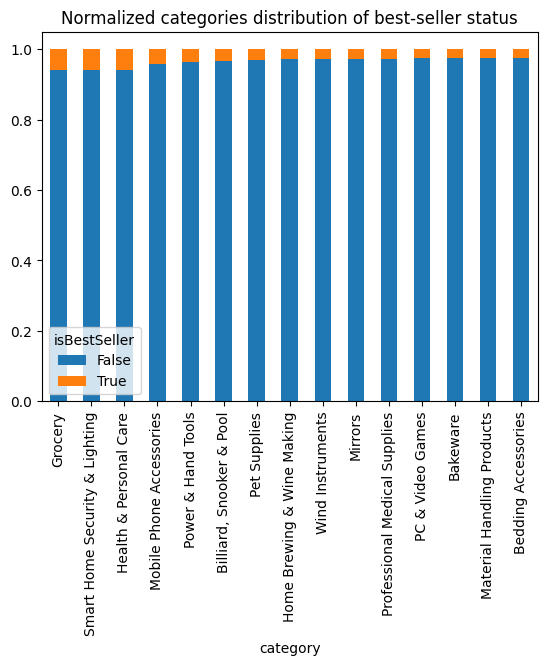

In [14]:
import matplotlib.pyplot as plt

crosstab_cat_bestseller = crosstab_norm.sort_values(True, ascending=False)[:15]
ax = crosstab_cat_bestseller.plot(kind='bar', stacked=True)
ax.set_title("Normalized categories distribution of best-seller status")
plt.show()

In [15]:
from IPython.display import Markdown

report = f"""
#### Conclusion: Visualization

The stacked bar provides an easy way to visualize the proportion of best-sellers to non-best-sellers within each category.

"""
display(Markdown(report))


#### Conclusion: Visualization

The stacked bar provides an easy way to visualize the proportion of best-sellers to non-best-sellers within each category.



---

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.


In [16]:
def filter_outliers(data, column = "price"):


    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    print("Lower bound: ", lower_bound)
    print("Upper bound: ", upper_bound)

    filtered_data = data[(data[column] >= lower_bound) & (data[column] <= upper_bound)]

    return filtered_data



In [17]:
filtered_price = filter_outliers(numeric_df)
filtered_df = filtered_price.join(df.category)
filtered_df

Lower bound:  -44.01
Upper bound:  99.99000000000001


,uid,stars,reviews,price,boughtInLastMonth,category
0,1,4.7,15308,21.99,0,Hi-Fi Speakers
1,2,4.7,98099,23.99,0,Hi-Fi Speakers
2,3,4.7,15308,21.99,0,Hi-Fi Speakers
3,4,4.7,7205,31.99,0,Hi-Fi Speakers
4,5,4.6,1881,17.99,0,Hi-Fi Speakers
...,...,...,...,...,...,...
2443646,2828589,0.0,0,22.34,0,Motorbike Clothing
2443647,2828590,0.0,0,97.99,0,Motorbike Clothing
2443648,2828591,0.0,0,52.99,0,Motorbike Clothing
2443649,2828592,4.3,404,79.99,0,Motorbike Clothing


In [18]:
# Top 20 categories based on count

top_20_count= filtered_df["category"].value_counts()[:20]
display(top_20_count)

top_20_count_cat = top_20_count.index.to_list()
print(top_20_count_cat)

category
Sports & Outdoors                         694092
Beauty                                     19233
Bath & Body                                19050
Manicure & Pedicure Products               18904
Handmade Clothing, Shoes & Accessories     18811
Make-up                                    18718
Skin Care                                  18686
Hair Care                                  18625
Birthday Gifts                             18398
Handmade Gifts                             17948
Handmade Home Décor                        17675
Luggage and travel gear                    17557
Women                                      17476
Fragrances                                 17431
Handmade Kitchen & Dining                  17346
Handmade Artwork                           17269
Handmade Home & Kitchen Products           17175
Handmade Jewellery                         17135
Men                                        16596
Baby                                       14883
Name: count

['Sports & Outdoors', 'Beauty', 'Bath & Body', 'Manicure & Pedicure Products', 'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care', 'Hair Care', 'Birthday Gifts', 'Handmade Gifts', 'Handmade Home Décor', 'Luggage and travel gear', 'Women', 'Fragrances', 'Handmade Kitchen & Dining', 'Handmade Artwork', 'Handmade Home & Kitchen Products', 'Handmade Jewellery', 'Men', 'Baby']


In [19]:
count_price_df = filtered_df[filtered_df.category.isin(top_20_count_cat)][["category", "price"]]
count_price_df = count_price_df.dropna().sort_values("price")
count_price_df

,category,price
342871,Sports & Outdoors,0.00
1532255,Sports & Outdoors,0.00
1025782,Sports & Outdoors,0.00
1531995,Sports & Outdoors,0.00
1422882,Sports & Outdoors,0.00
...,...,...
123741,Handmade Gifts,99.99
900942,Sports & Outdoors,99.99
2026117,Sports & Outdoors,99.99
2105274,Sports & Outdoors,99.99


In [20]:
# order by median
order = count_price_df.groupby("category").median().sort_values("price").index.to_list()
order


['Make-up',
 'Manicure & Pedicure Products',
 'Beauty',
 'Handmade Clothing, Shoes & Accessories',
 'Hair Care',
 'Handmade Home & Kitchen Products',
 'Bath & Body',
 'Handmade Home Décor',
 'Skin Care',
 'Handmade Kitchen & Dining',
 'Baby',
 'Handmade Gifts',
 'Luggage and travel gear',
 'Birthday Gifts',
 'Handmade Artwork',
 'Handmade Jewellery',
 'Women',
 'Sports & Outdoors',
 'Fragrances',
 'Men']

/var/folders/xm/3ksp3z452z1fgpzrq_nfylnm0000gp/T/ipykernel_47582/2702219216.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=count_price_df,


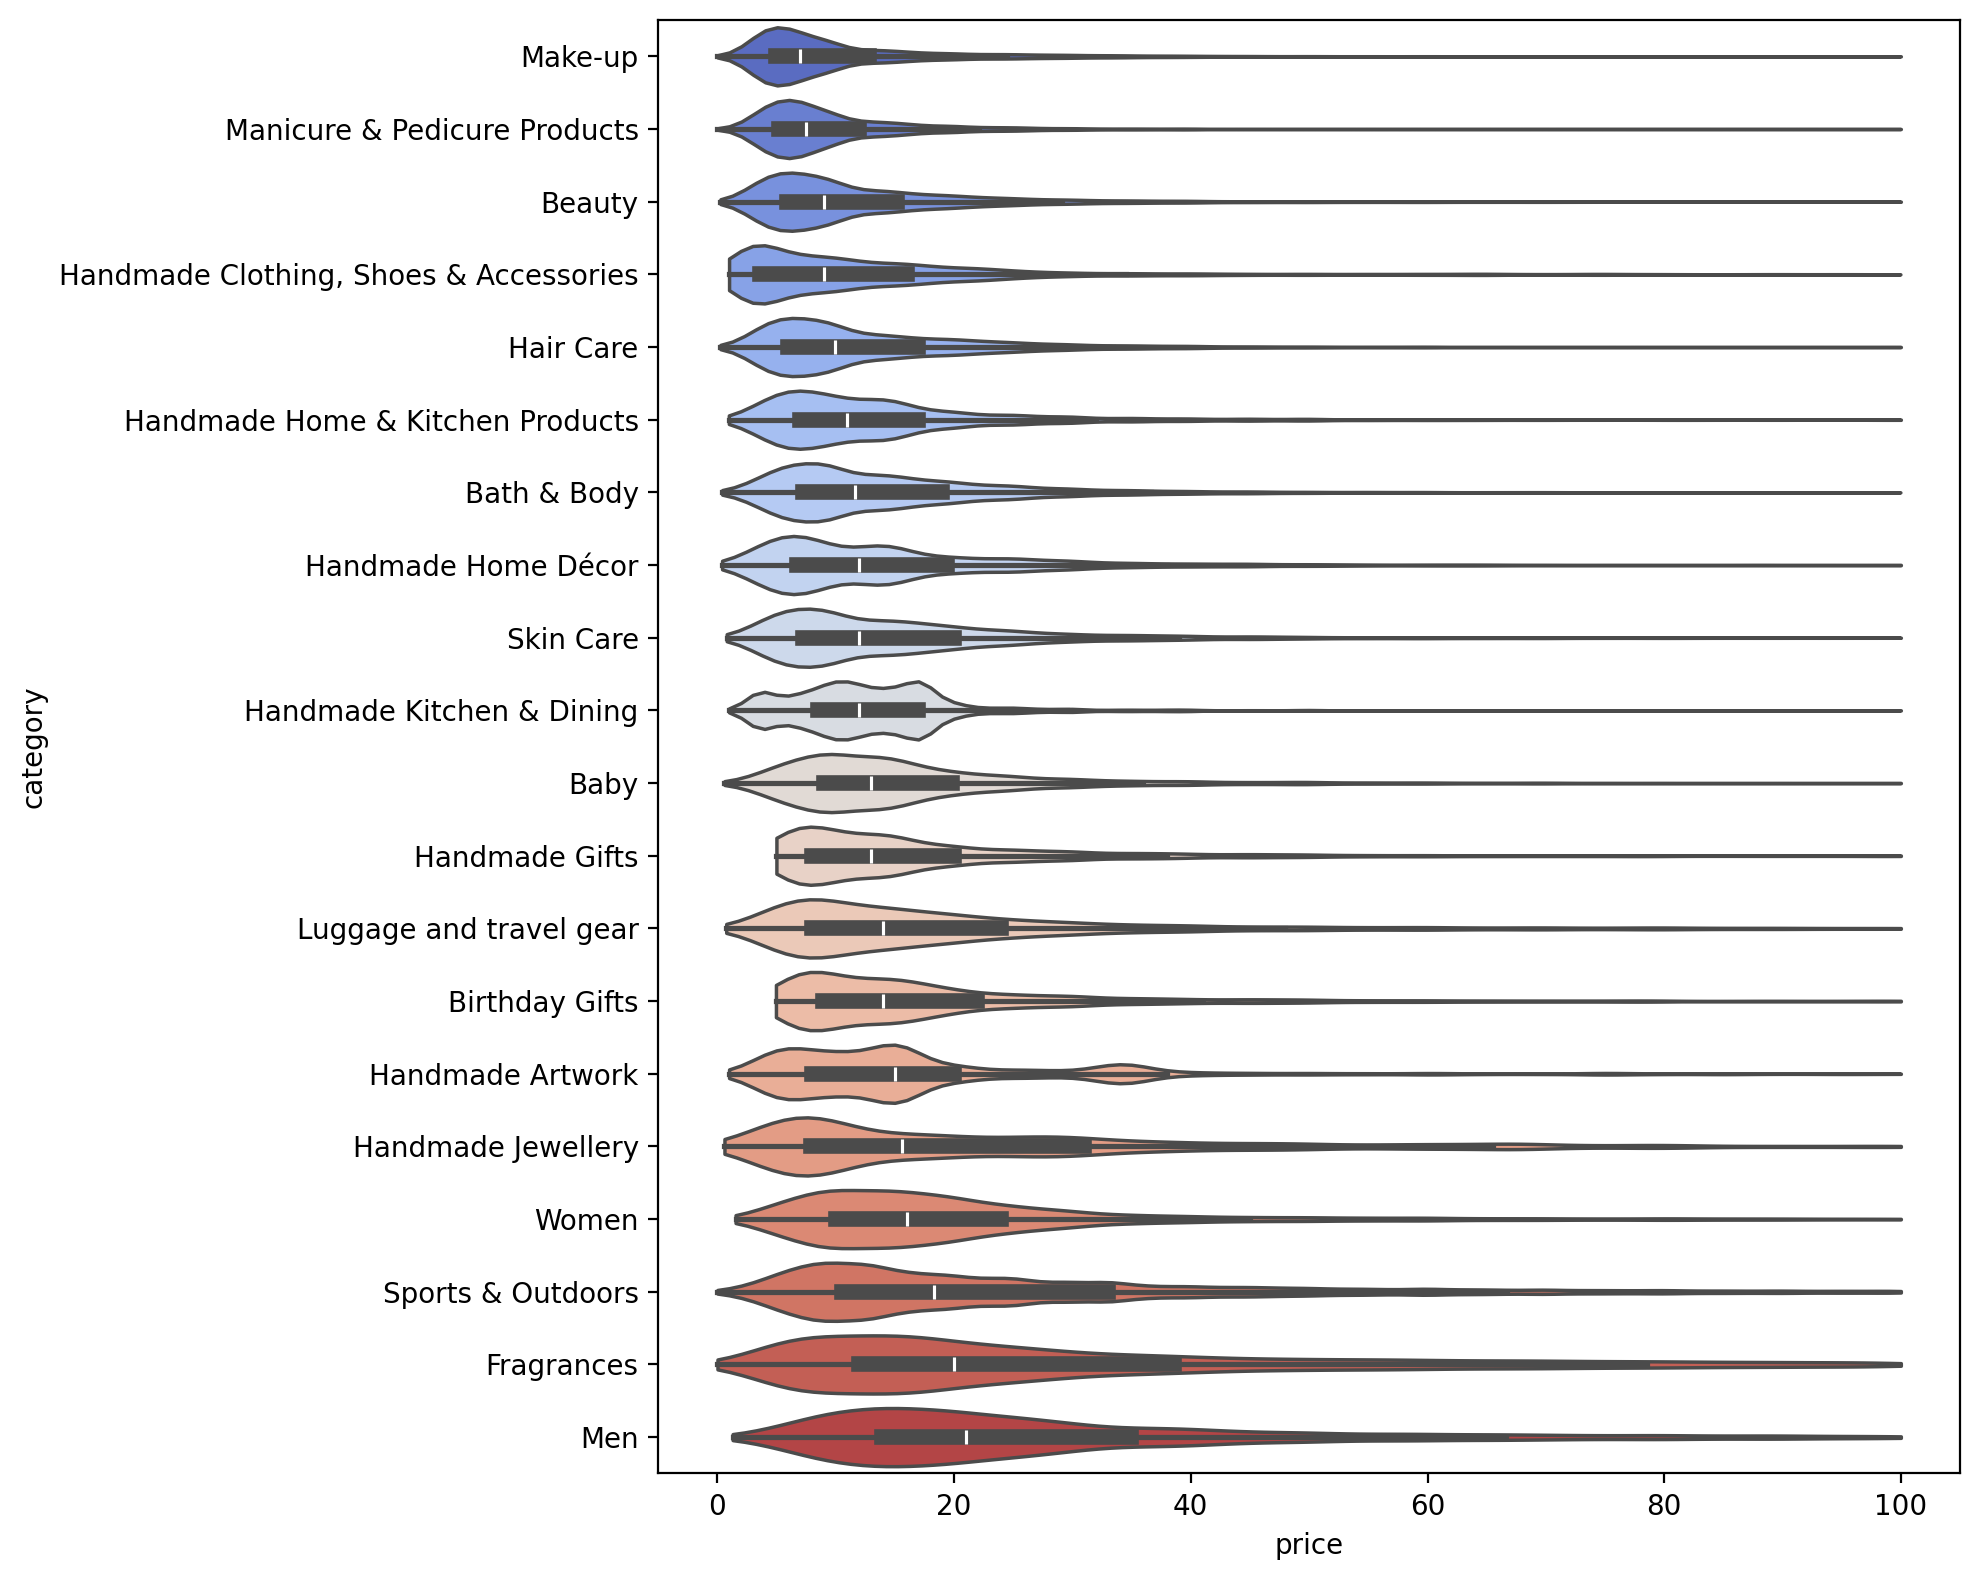

In [21]:
# Violin plots
import matplotlib.pylab as plt
%matplotlib inline
plt.rcParams['figure.dpi'] = 200
fig=plt.figure(figsize=(10, 8))

sns.violinplot(data=count_price_df,
                y="category",
                x="price",
                palette="coolwarm",
                legend=False,
                order=order,
                cut = 0,)

plt.tight_layout()
plt.show()

In [22]:
# Top 20 categories based on medium price

top_20_most_expensive_median= filtered_df.groupby("category").median().sort_values("price", ascending = False)[:20]
display(top_20_most_expensive_median)


,uid,stars,reviews,price,boughtInLastMonth
category,,,,,
Desktop PCs,2233906.0,4.0,5.0,74.000,0.0
Boxing Shoes,1836662.0,0.0,0.0,69.790,0.0
Tablets,1536287.5,0.0,0.0,69.000,0.0
Graphics Cards,348832.0,4.1,14.0,68.540,0.0
Motherboards,349351.5,4.4,89.5,67.920,0.0
Made in Italy Handmade,891334.0,0.0,0.0,64.000,0.0
Digital Frames,2581418.5,3.6,1.0,63.900,0.0
Streaming Clients,2817220.5,0.0,0.0,62.680,0.0
Golf Shoes,1830985.0,0.0,0.0,62.390,0.0


In [23]:
from IPython.display import Markdown

report = f"""
#### Conclusion: Violin plots

The violin plot is a tool to observe the distribution shape of the price
within each category. We remove the outliers to avoid a distorting the shape of the distribution.

The violin plots show skewed distributions for all categories, medians not centered in the mean.
Some categories, like 'Handmade Kitchen & Dinning' present many peaks, different from the usual bell curve.

Additionally, the category with highest median price in the violin plot (the top 20 categories considering the count)
is 'Men', with median price a bit over 20.

The price category that tends to have the highest median price is 
{top_20_most_expensive_median.iloc[0].name} with a median price of 
{top_20_most_expensive_median.iloc[0].price} pounds.

"""
display(Markdown(report))


#### Conclusion: Violin plots

The violin plot is a tool to observe the distribution shape of the price
within each category. We remove the outliers to avoid a distorting the shape of the distribution.

The violin plots show skewed distributions for all categories, medians not centered in the mean.
Some categories, like 'Handmade Kitchen & Dinning' present many peaks, different from the usual bell curve.

Additionally, the category with highest median price in the violin plot (the top 20 categories considering the count)
is 'Men', with median price a bit over 20.

The price category that tends to have the highest median price is 
Desktop PCs with a median price of 
74.0 pounds.



2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.


In [24]:
# Top 10 categories based on count

top_10_cat = top_20_count_cat[:10]
top_10_df = filtered_df[["category", "price"]][filtered_df.category.isin(top_10_cat)]

top_10_df

,category,price
82163,Sports & Outdoors,6.49
82164,Sports & Outdoors,49.99
82167,Sports & Outdoors,16.98
82168,Sports & Outdoors,19.95
82169,Sports & Outdoors,49.99
...,...,...
2429088,Sports & Outdoors,99.67
2429089,Sports & Outdoors,20.62
2429090,Sports & Outdoors,59.86
2437153,Sports & Outdoors,14.99


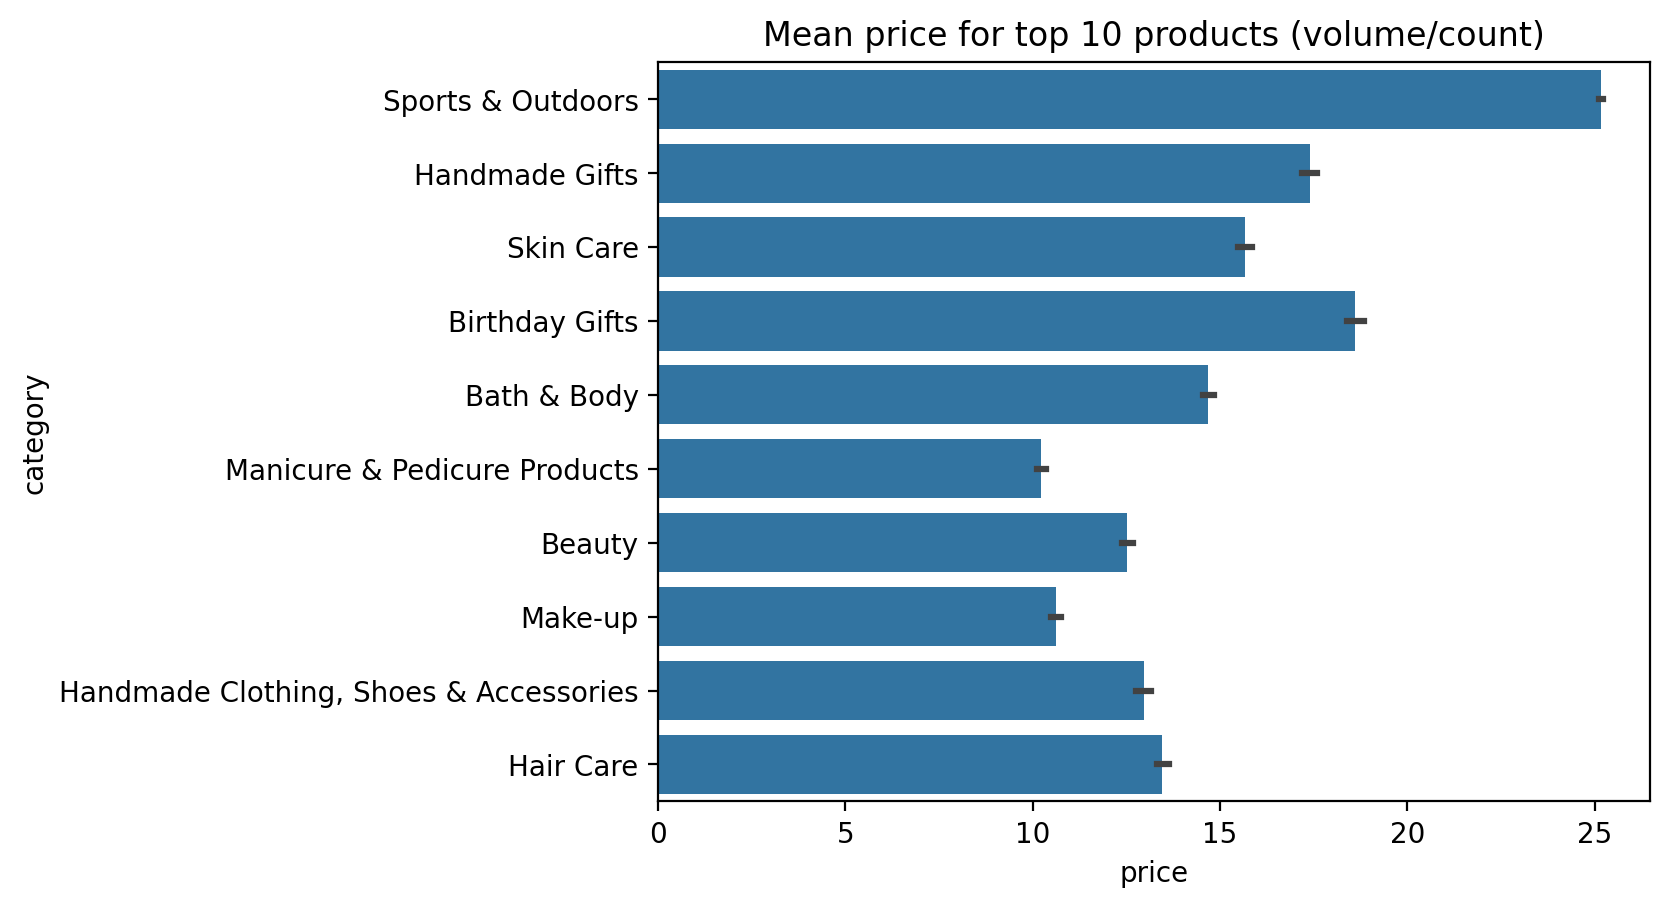

In [25]:
import matplotlib.pyplot as plt

ax = sns.barplot(top_10_df, y="category", x= "price", estimator="mean")
ax.set_title("Mean price for top 10 products (volume/count)")
plt.show()

In [26]:
top_20_most_expensive = filtered_df.groupby("category").mean().sort_values("price", ascending = False)[:10]
display(top_20_most_expensive.reset_index()[["category", "price"]])


,category,price
0,Motherboards,68.772432
1,Boxing Shoes,67.417803
2,Desktop PCs,66.915562
3,Tablets,66.552971
4,Graphics Cards,65.103509
5,Digital Frames,60.745129
6,Streaming Clients,60.241803
7,Hockey Shoes,60.094796
8,Computer Cases,58.339884
9,Skiing Poles,57.867770


In [27]:
from IPython.display import Markdown

report = f"""
#### Conclusion: Bar charts
The category with highest mean from the top 10 categories based on count was 'Sports & Outdoors', 
with a mean of approximately 25 pounds. 
The price category that tends to have the highest mean price overall is {top_20_most_expensive.iloc[0].name} 
with a mean price of {round(top_20_most_expensive.iloc[0].price, 2)} pounds.

"""
display(Markdown(report))


#### Conclusion: Bar charts
The category with highest mean from the top 10 categories based on count was 'Sports & Outdoors', 
with a mean of approximately 25 pounds. 
The price category that tends to have the highest mean price overall is Motherboards 
with a mean price of 68.77 pounds.



3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.


In [28]:
# Ratings of top 10 categories based on count (top_10_cat)
#  - Filtered price outliers
#  - Filtered products with no rating (star = 0)

ratings = filtered_df[filtered_df.stars !=0]
display(ratings)

ratings_top_10 = ratings[ratings.category.isin(top_10_cat)]
display(ratings_top_10)


,uid,stars,reviews,price,boughtInLastMonth,category
0,1,4.7,15308,21.99,0,Hi-Fi Speakers
1,2,4.7,98099,23.99,0,Hi-Fi Speakers
2,3,4.7,15308,21.99,0,Hi-Fi Speakers
3,4,4.7,7205,31.99,0,Hi-Fi Speakers
4,5,4.6,1881,17.99,0,Hi-Fi Speakers
...,...,...,...,...,...,...
2443639,2828580,3.6,25,49.99,0,Motorbike Clothing
2443642,2828585,3.6,66,49.99,0,Motorbike Clothing
2443644,2828587,3.6,12,14.99,0,Motorbike Clothing
2443649,2828592,4.3,404,79.99,0,Motorbike Clothing


,uid,stars,reviews,price,boughtInLastMonth,category
82163,89483,4.2,3116,6.49,0,Sports & Outdoors
82164,89484,4.2,2594,49.99,0,Sports & Outdoors
82167,89487,4.5,9879,16.98,0,Sports & Outdoors
82168,89488,4.7,1223,19.95,0,Sports & Outdoors
82169,89489,4.2,55,49.99,0,Sports & Outdoors
...,...,...,...,...,...,...
2397634,2767899,4.0,1,71.65,0,Sports & Outdoors
2397652,2767930,4.4,37,26.38,0,Sports & Outdoors
2429090,2806952,4.3,3,59.86,0,Sports & Outdoors
2437153,2818782,4.2,554,14.99,0,Sports & Outdoors


In [29]:
order = ratings_top_10.groupby("category").median().sort_values("stars").index.to_list()
order

['Make-up',
 'Manicure & Pedicure Products',
 'Beauty',
 'Hair Care',
 'Skin Care',
 'Sports & Outdoors',
 'Bath & Body',
 'Birthday Gifts',
 'Handmade Gifts',
 'Handmade Clothing, Shoes & Accessories']

/var/folders/xm/3ksp3z452z1fgpzrq_nfylnm0000gp/T/ipykernel_47582/4122973408.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ratings_top_10,


<Axes: xlabel='stars', ylabel='category'>

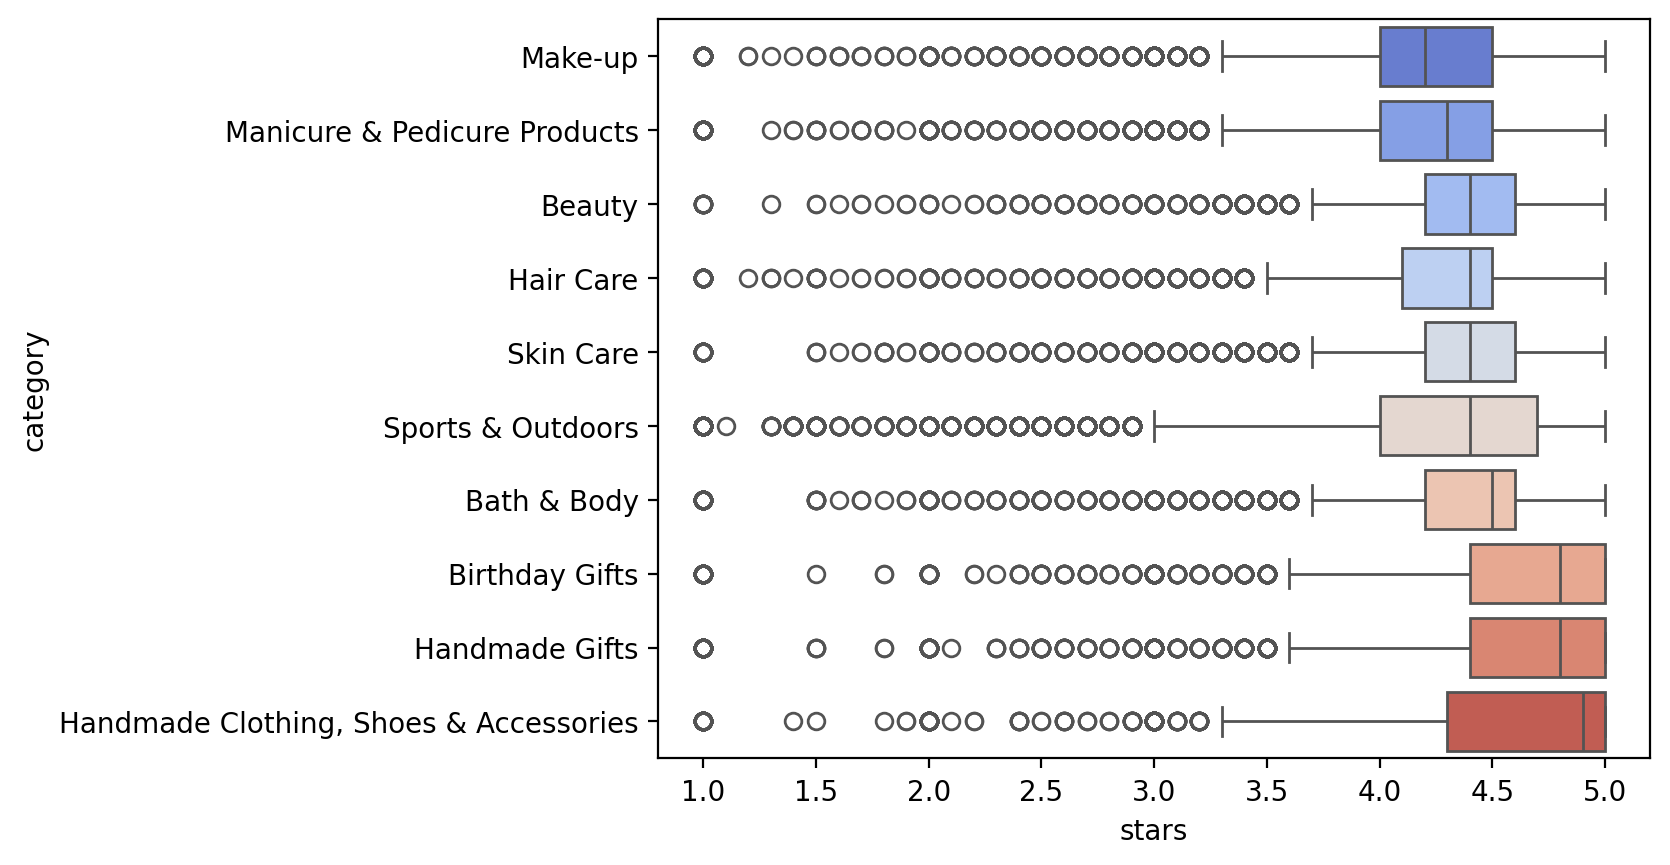

In [30]:
sns.boxplot(ratings_top_10,
            y = "category",
            x = "stars",
            palette="coolwarm",
            legend=False,
            order = order)

In [31]:
# Highest Median among all dataset (filtering out the price outliers and products without rating)
top_10_median_ratings = ratings[["category", "stars"]].groupby("category").median().sort_values( "stars", ascending = False)[:10]
top_10_median_ratings

,stars
category,
Made in Italy Handmade,5.0
Handmade Baby Products,5.0
Handmade Artwork,5.0
Handmade Kitchen & Dining,4.9
"Handmade Clothing, Shoes & Accessories",4.9
Handmade Gifts,4.8
Birthday Gifts,4.8
Handmade Home Décor,4.8
Handmade Home & Kitchen Products,4.7


In [32]:
from IPython.display import Markdown
top_categories = ", ".join(top_10_median_ratings.index.to_list())
n_handmade = sum([1 if "handmade" in item.lower() else 0 for item in top_10_median_ratings.index.to_list()])
rating_range = top_10_median_ratings.stars.max() - top_10_median_ratings.stars.min()

report = f"""
#### Conclusion: Box plots

The boxplots for the top 10 categories based on count show high median ratings, in which all of then are over 4.0 stars.
The boxplots also show a high number of outliers on the left side (under 3.5 stars).

The 10 categories with highest median ratings, excluding the products with outlier prices, were {top_categories}.
A important insight we can extract from the analysis is that {n_handmade} out of 10 products are described as handmade.
Since this is a strong incidence, there might be a correlation between the item being handmade and having higher ratings.
Additionally, there is a small range of the ratings in the top 10, {round(rating_range, 2)}, which represent really strong evaluations.
"""
display(Markdown(report))


#### Conclusion: Box plots

The boxplots for the top 10 categories based on count show high median ratings, in which all of then are over 4.0 stars.
The boxplots also show a high number of outliers on the left side (under 3.5 stars).

The 10 categories with highest median ratings, excluding the products with outlier prices, were Made in Italy Handmade, Handmade Baby Products, Handmade Artwork, Handmade Kitchen & Dining, Handmade Clothing, Shoes & Accessories, Handmade Gifts, Birthday Gifts, Handmade Home Décor, Handmade Home & Kitchen Products, Gifts for Him.
A important insight we can extract from the analysis is that 8 out of 10 products are described as handmade.
Since this is a strong incidence, there might be a correlation between the item being handmade and having higher ratings.
Additionally, there is a small range of the ratings in the top 10, 0.3, which represent really strong evaluations.


In [33]:
# Correlation between price and ratings(stars)
# filtering the price outliers and products without ratings

# Pearson (-1,1)
print("Pearson correlation (price, stars): ")
pearson_corr = round(float(ratings["price"].corr(ratings["stars"], method="pearson")), 2)
print(pearson_corr)

# Spearman (-1,1)
print("Spearman correlation (price, stars): ")
spearman_corr = round(float(ratings["price"].corr(ratings["stars"], method="spearman")), 2)
print(spearman_corr)


Pearson correlation (price, stars): 
0.01
Spearman correlation (price, stars): 
0.02


In [34]:
# Correlation between price and ratings(stars) top 10
# filtering the price outliers and products without ratings

top_10_median_df = ratings[ratings.category.isin(top_10_median_ratings.index.to_list())]
        
# Pearson (-1,1)
print("Pearson correlation (price, stars): ")
pearson_corr_top = round(float(top_10_median_df["price"].corr(ratings["stars"], method="pearson")), 2)
print(pearson_corr_top)

# Spearman (-1,1)
print("Spearman correlation (price, stars): ")
spearman_corr_top = round(float(top_10_median_df["price"].corr(ratings["stars"], method="spearman")), 2)
print(spearman_corr_top)


Pearson correlation (price, stars): 
0.03
Spearman correlation (price, stars): 
0.07


In [35]:
from IPython.display import Markdown

report = f"""
#### Conclusion: Correlation Coefficients
 
The correlations for the complete dataset were: Pearson with {pearson_corr}, and Spearman with {spearman_corr}.
Both correlations are positive and demonstrate values close to 0, which indicate a small correlation.

When we filter the ratings by the top 10 median ratings, we find that the correlation increased for both Pearson({pearson_corr_top}) and Spearman ({spearman_corr_top}).
Even so, the correlations are inferior to 0.1.  

Thus, the price and the ratings(stars) are weakly positively correlated, or there is no linear or monotonic relationship.

"""
display(Markdown(report))



#### Conclusion: Correlation Coefficients

The correlations for the complete dataset were: Pearson with 0.01, and Spearman with 0.02.
Both correlations are positive and demonstrate values close to 0, which indicate a small correlation.

When we filter the ratings by the top 10 median ratings, we find that the correlation increased for both Pearson(0.03) and Spearman (0.07).
Even so, the correlations are inferior to 0.1.  

Thus, the price and the ratings(stars) are weakly positively correlated, or there is no linear or monotonic relationship.



[]

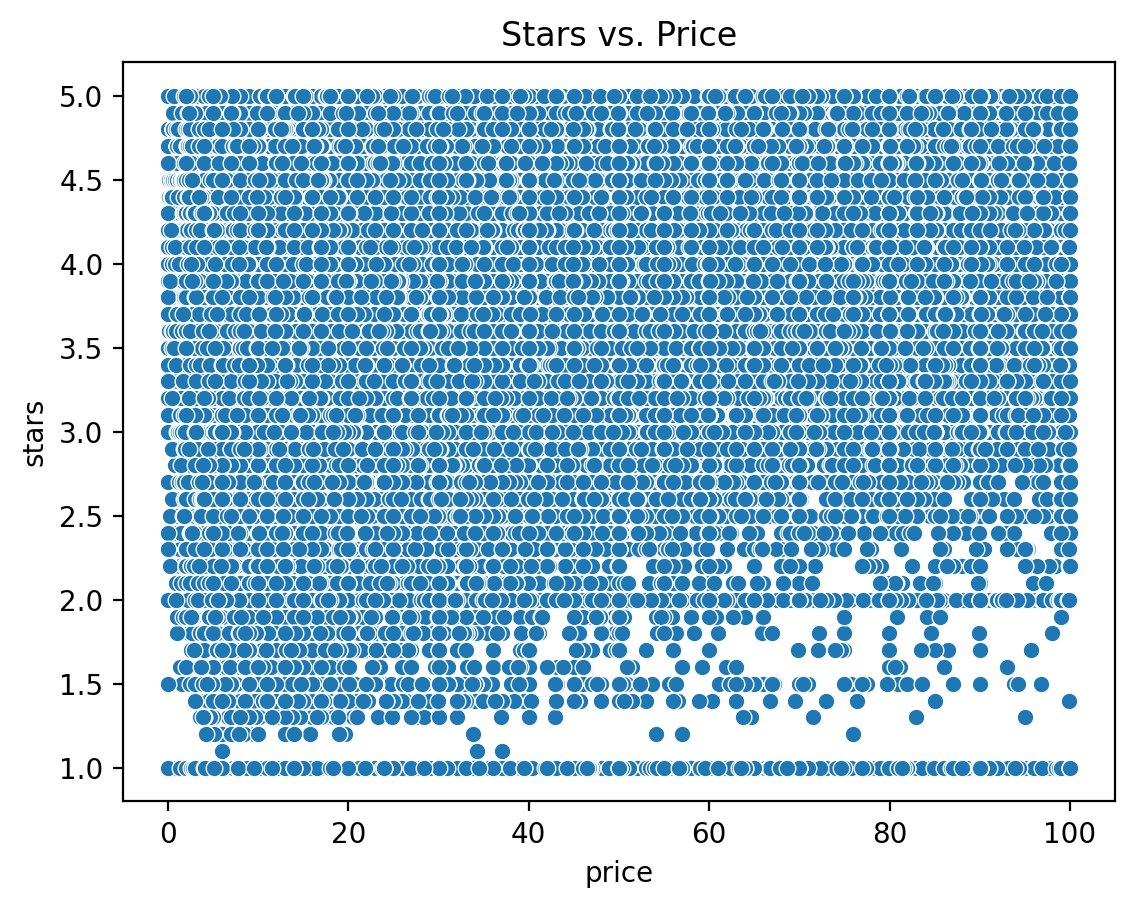

In [36]:
ax = sns.scatterplot(ratings, x = "price", y = "stars")
ax.set_title("Stars vs. Price")
plt.plot()

[]

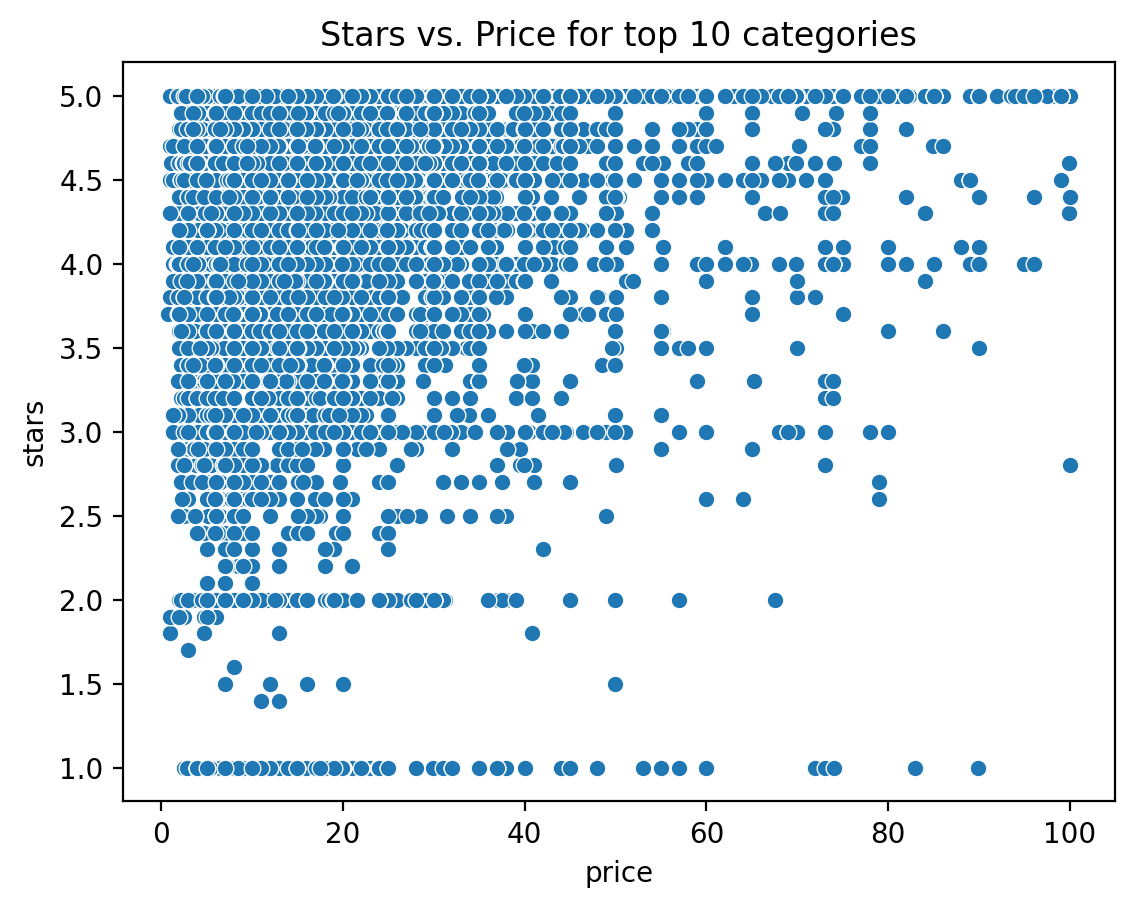

In [37]:
# Top 10 categories based on medium ratings
ax = sns.scatterplot(ratings[ratings.category.isin(top_10_median_ratings.index.to_list())], x = "price", y = "stars")
ax.set_title("Stars vs. Price for top 10 categories")
plt.plot()

<Axes: xlabel='price', ylabel='stars'>

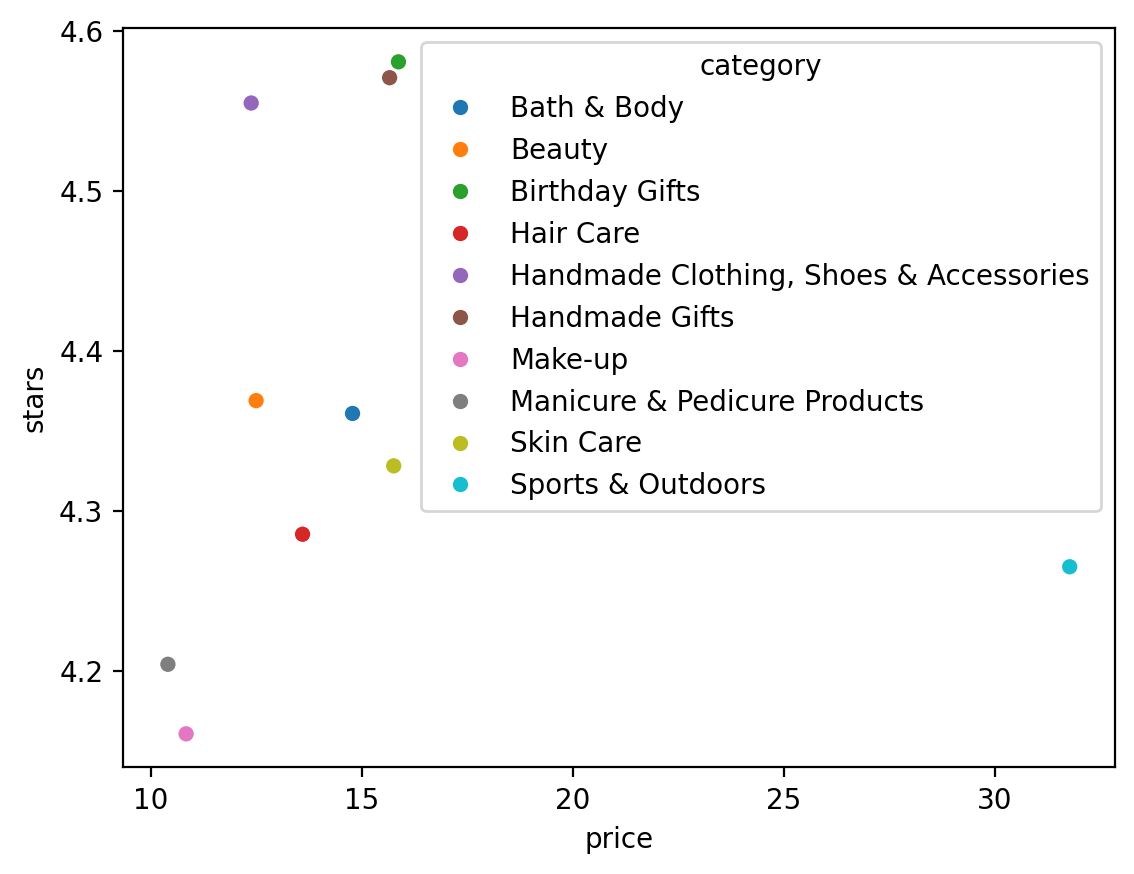

In [38]:
# Scatterplot mean by category

sns.scatterplot(ratings_top_10.groupby("category").mean(), x = "price", y = "stars", hue="category")

In [39]:
from IPython.display import Markdown

report = f"""
#### Conclusion: Scatterplot Visualizations

The scatter plot visualization confirms the low correlation observed in the pearson and spearman tests.
The scatter plot for all of the ratings shows no pattern. However, when we filter the data to show
the scatter plot of the top 10 categories based on median rating (stars), some of the randomnes is filtered.
For the top 10 categories, the points are more concentrated under a price of 50 pounds, and from 2.5 starts to 5.

A possible insight we can extract from that, is that the distribution might change considering individual
categories and patterns can be better identified.
"""
display(Markdown(report))



#### Conclusion: Scatterplot Visualizations

The scatter plot visualization confirms the low correlation observed in the pearson and spearman tests.
The scatter plot for all of the ratings shows no pattern. However, when we filter the data to show
the scatter plot of the top 10 categories based on median rating (stars), some of the randomnes is filtered.
For the top 10 categories, the points are more concentrated under a price of 50 pounds, and from 2.5 starts to 5.

A possible insight we can extract from that, is that the distribution might change considering individual
categories and patterns can be better identified.


In [40]:
numeric_filtered = ratings.copy().drop(["category", "uid"], axis = 1)
corr = numeric_filtered.corr()
corr

,stars,reviews,price,boughtInLastMonth
stars,1.000000,0.033487,0.006745,0.039851
reviews,0.033487,1.000000,-0.003168,0.097969
price,0.006745,-0.003168,1.000000,-0.073517
boughtInLastMonth,0.039851,0.097969,-0.073517,1.000000


Text(0.5, 1.0, 'Correlation between the numerical variables')

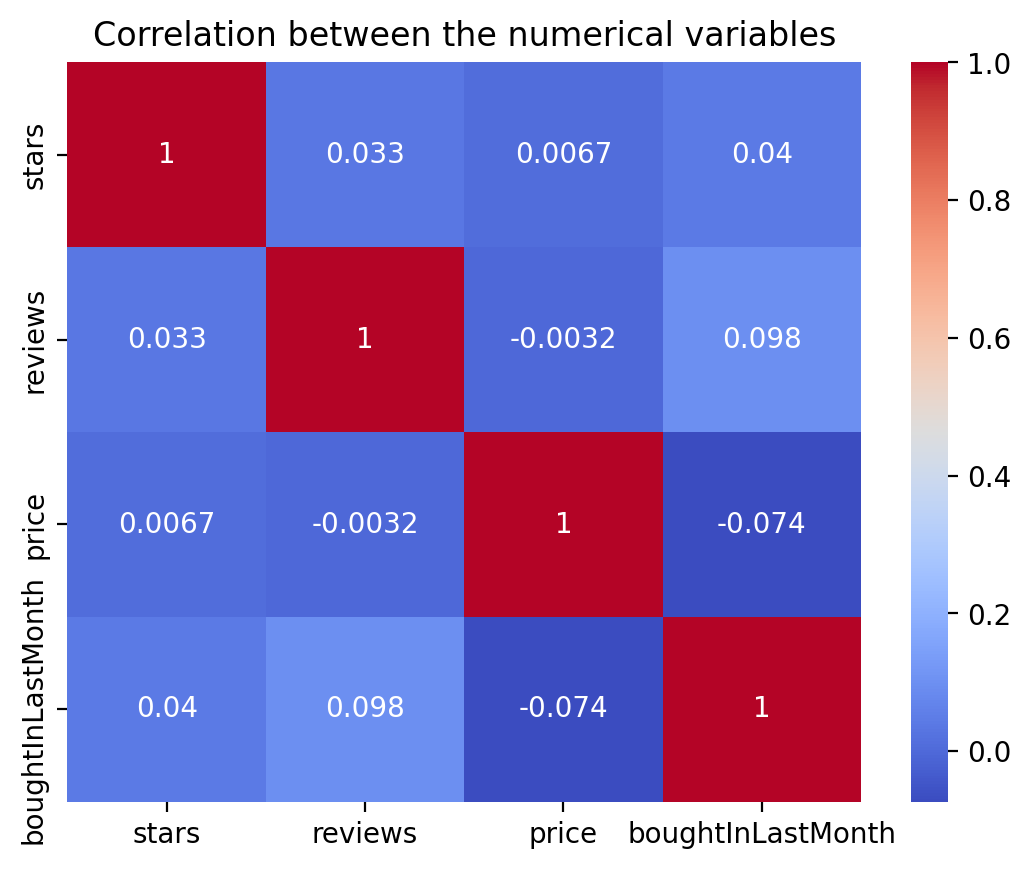

In [41]:

ax = sns.heatmap(corr, annot=True, cmap="coolwarm")
ax.set_title("Correlation between the numerical variables")

In [42]:
from IPython.display import Markdown

report = f"""
#### Conclusion: Heatmap

From the heatmap no significant correlation is observed between the numerical variables. 

"""
display(Markdown(report))



#### Conclusion: Heatmap

From the heatmap no significant correlation is observed between the numerical variables. 



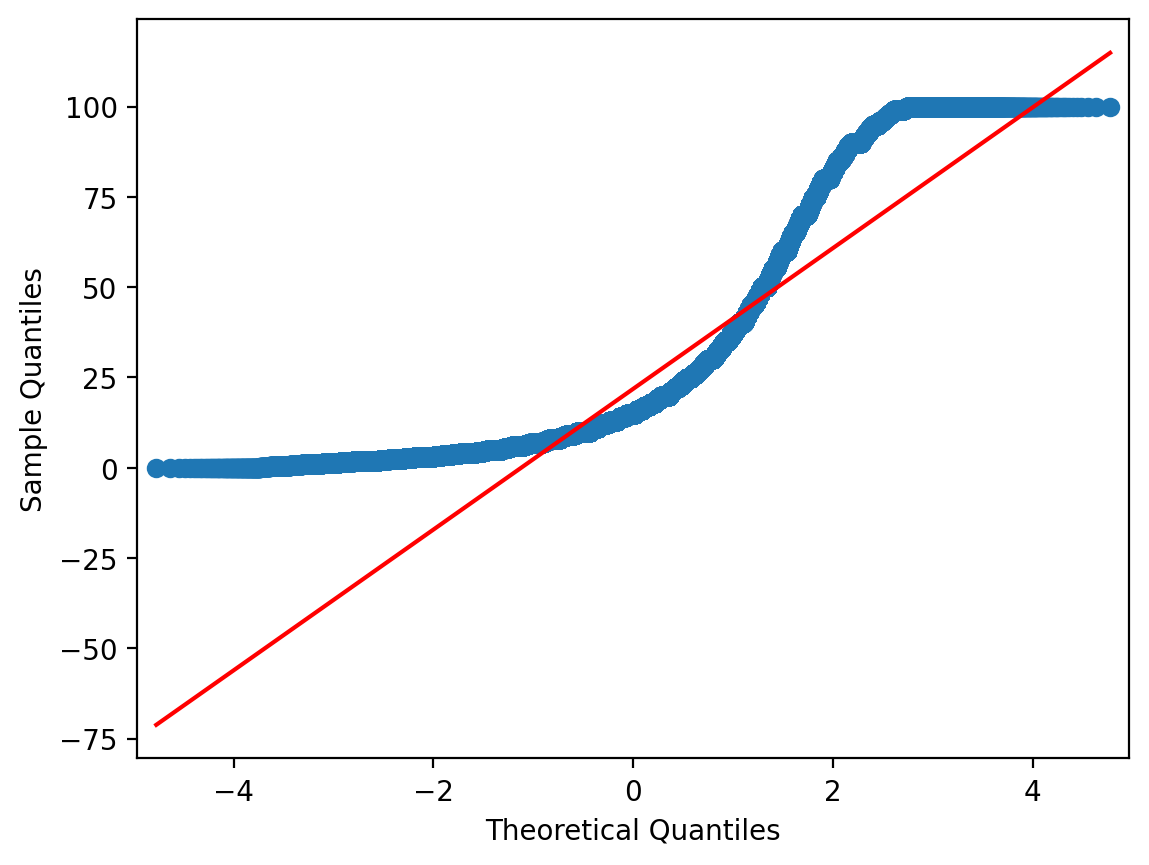

In [43]:
# qq plot

import statsmodels.api as sm

# Generating a Q-Q plot for 'SalePrice' to check if its distribution follows a normal distribution
sm.qqplot(ratings['price'], line='s')
plt.show()

In [44]:
from IPython.display import Markdown

report = f"""
#### Conclusion: QQ plot

The qq plot shows that the prices do not follow a normal distribution. The points form a S-shape,
diverging from the expected line.

"""
display(Markdown(report))



#### Conclusion: QQ plot

The qq plot shows that the prices do not follow a normal distribution. The points form a S-shape,
diverging from the expected line.



### Additional Exploration

In [45]:
blob = ratings.copy().join(categorical_df.isBestSeller)
blob

,uid,stars,reviews,price,boughtInLastMonth,category,isBestSeller
0,1,4.7,15308,21.99,0,Hi-Fi Speakers,False
1,2,4.7,98099,23.99,0,Hi-Fi Speakers,True
2,3,4.7,15308,21.99,0,Hi-Fi Speakers,False
3,4,4.7,7205,31.99,0,Hi-Fi Speakers,False
4,5,4.6,1881,17.99,0,Hi-Fi Speakers,False
...,...,...,...,...,...,...,...
2443639,2828580,3.6,25,49.99,0,Motorbike Clothing,False
2443642,2828585,3.6,66,49.99,0,Motorbike Clothing,False
2443644,2828587,3.6,12,14.99,0,Motorbike Clothing,False
2443649,2828592,4.3,404,79.99,0,Motorbike Clothing,False


/var/folders/xm/3ksp3z452z1fgpzrq_nfylnm0000gp/T/ipykernel_47582/3951725667.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=blob[["isBestSeller", "stars"]],


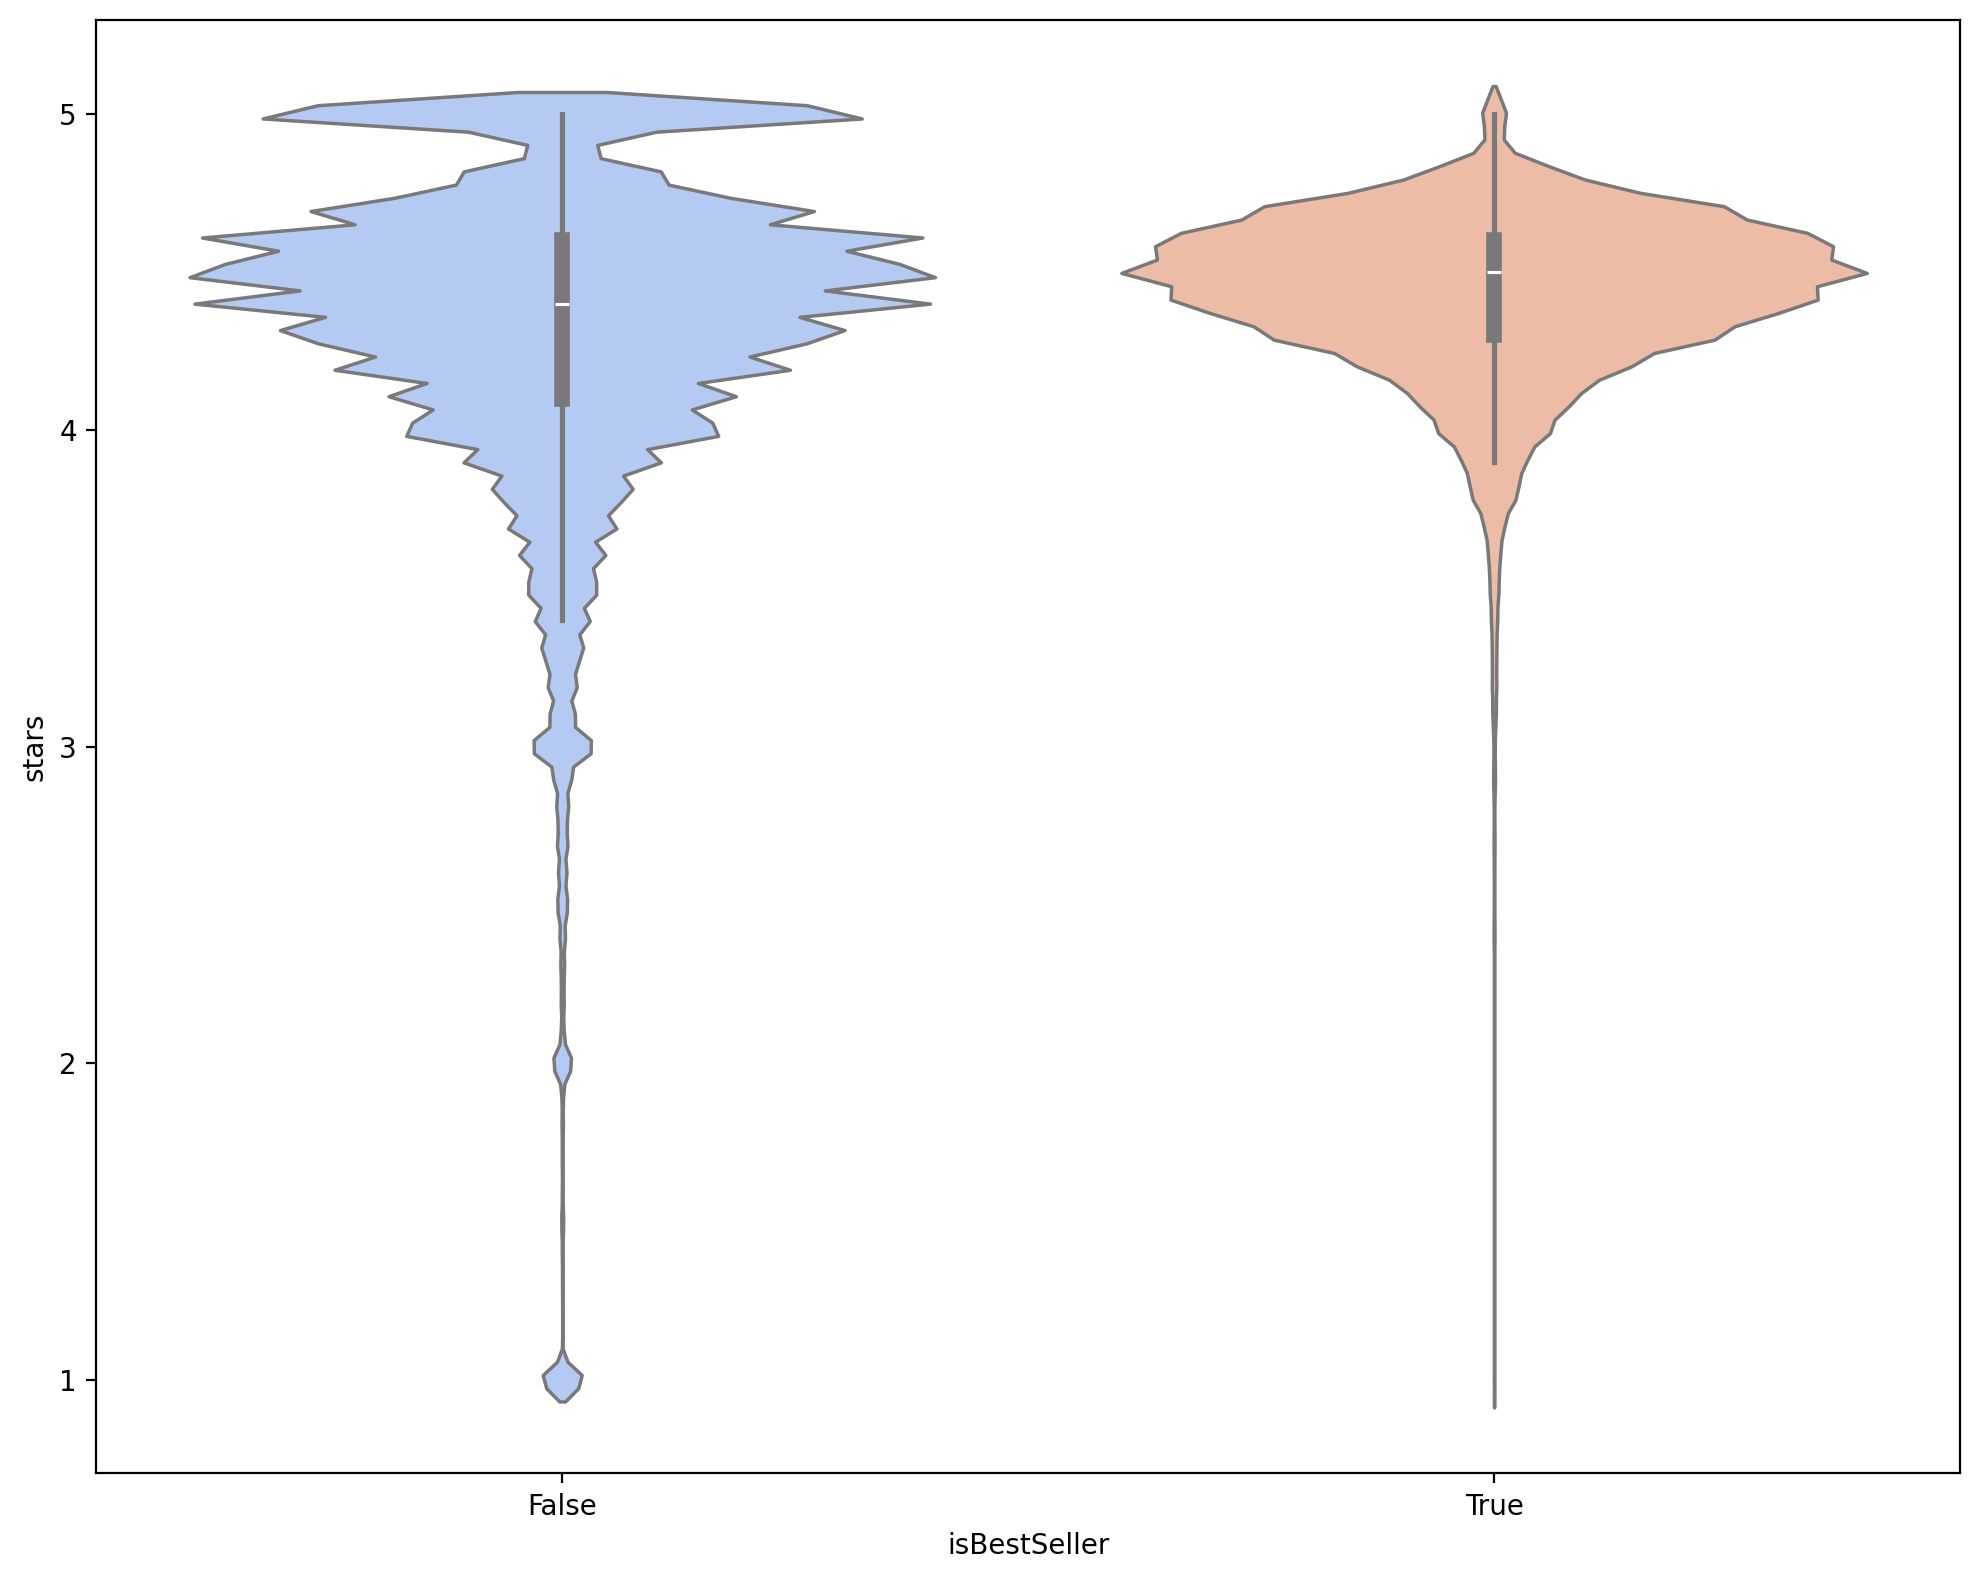

In [46]:
# Violin plots
import matplotlib.pylab as plt
%matplotlib inline
plt.rcParams['figure.dpi'] = 200
fig=plt.figure(figsize=(10, 8))

sns.violinplot(data=blob[["isBestSeller", "stars"]],
                x="isBestSeller",
                y="stars",
                palette="coolwarm",
                legend=False,
                )

plt.tight_layout()
plt.show()

<Axes: xlabel='price', ylabel='stars'>

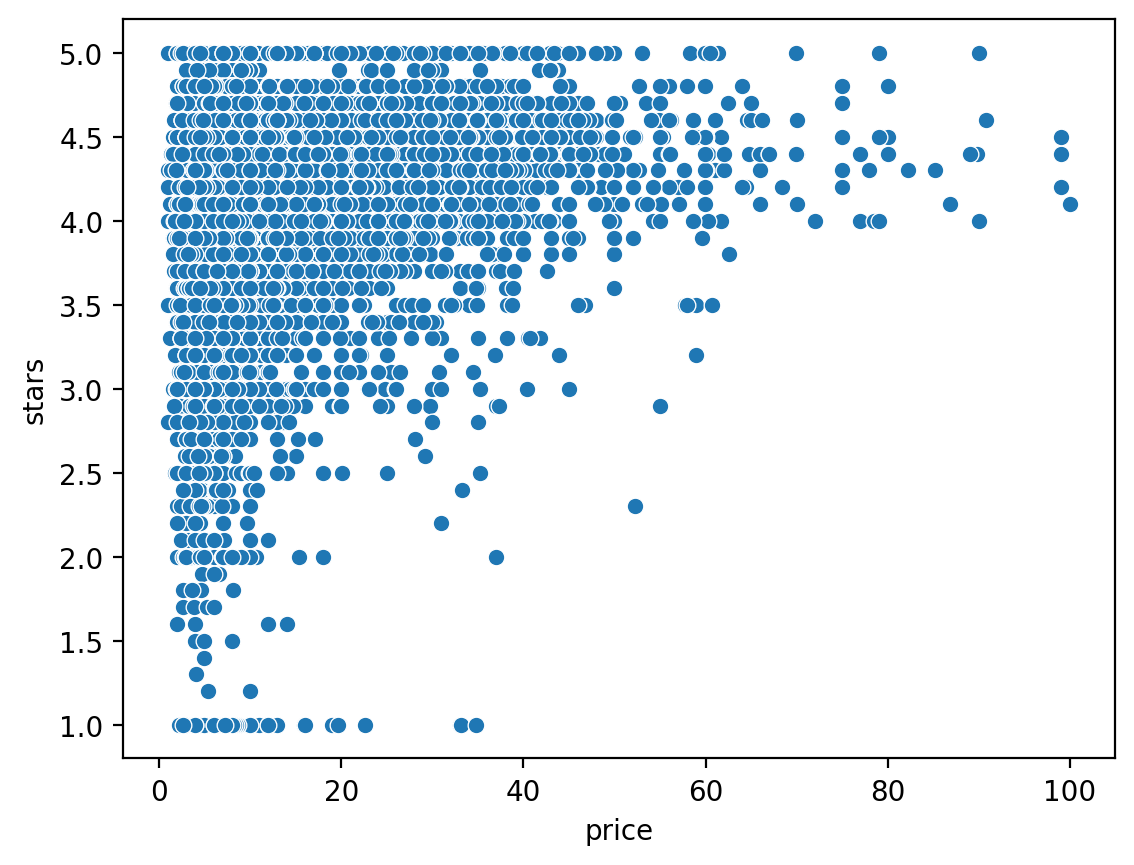

In [47]:
blob_1 = ratings[ratings.category == "Make-up"]
blob_1
sns.scatterplot(blob_1, x = "price", y = "stars")

<Axes: xlabel='price', ylabel='stars'>

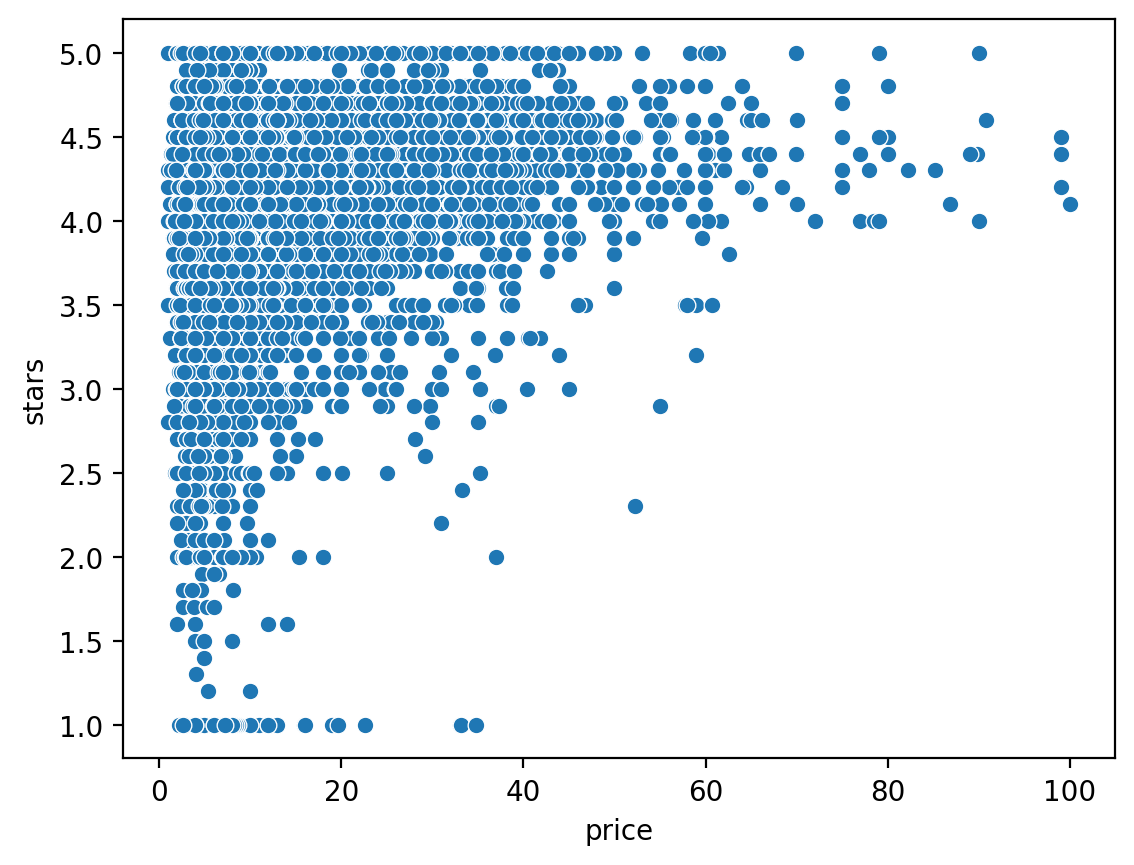

In [48]:
blob_2 = ratings[ratings.category == "Sports & Outdoors"]
blob_2
sns.scatterplot(blob_1, x = "price", y = "stars")